# 6. Nonlinear dynamical model

PyLBM-Isca is a *linear* model, but it is the linearisation of a specific
nonlinear core, and it keeps **one** nonlinear term — the kinetic energy
$\tfrac12(u'^2+v'^2)$ in the divergence equation, exactly as Isca does. This
chapter isolates that term, verifies that the rest of the operator is the *exact*
tangent-linear of the model's own tendency, and shows when the retained
nonlinearity matters. It is the PyLBM-Isca analogue of the WK guide's nonlinear
run (their Ch. 6), where a residual forcing $R$ holds the basic state steady so
the nonlinear model evolves only the perturbation.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "4")
root = os.path.abspath("")
while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "pylbm_isca")):
    root = os.path.dirname(root)
sys.path.insert(0, root)
sys.path.insert(0, os.path.join(root, "docs", "book"))
import numpy as np
import matplotlib.pyplot as plt
from pylbm_isca import Config, LBM, Spectral, VerticalGrid
from pylbm_isca.backend import asnumpy, gpu_available
import lbmtools as lt

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(nlon=64, nlat=32, nmax=21, device=DEVICE)   # T21 L20, runs offline
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = sp.lon_deg, sp.lat_deg, asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

PyLBM-Isca  T21  64x32  L20  backend=gpu


In [2]:
from pylbm_isca.dynamics import BasicStateTerms, Dynamics
from pylbm_isca.state import State

bs  = lt.baroclinic_jet(sp, vg, umax=40.0)
bst = BasicStateTerms(sp, vg, bs)
dyn_lin  = Dynamics(sp, vg, bst, strictly_linear=True)    # exact tangent-linear
dyn_full = Dynamics(sp, vg, bst, strictly_linear=False)   # keeps 0.5(u'^2+v'^2)

VARS = ["vor", "div", "T", "pi", "q"]    # order of dyn.tendencies(): vor,div,t,pi,q
rng = np.random.default_rng(0)
def smooth(scale, shape):
    g = asnumpy(sp.wave_to_grid(sp.grid_to_wave(rng.standard_normal(shape))))
    return scale*g/(np.abs(g).max() or 1.0)
dirn = (smooth(1.0, (sp.nlat, sp.nlon, vg.kmax)),      # u'  ~1 m/s
        smooth(1.0, (sp.nlat, sp.nlon, vg.kmax)),      # v'
        smooth(1.0, (sp.nlat, sp.nlon, vg.kmax)),      # T'  ~1 K
        smooth(1e-3, (sp.nlat, sp.nlon, vg.kmax)),     # q'
        smooth(1e-3, (sp.nlat, sp.nlon)))              # pi'

def state_at(a):
    u0, v0, t0, q0, p0 = dirn
    st = State.zeros(np.asarray(bs.ps), vg.kmax, xp=sp.xp)
    st.u = sp.xp.asarray(a*u0); st.v = sp.xp.asarray(a*v0)
    st.t = sp.xp.asarray(a*t0); st.q = sp.xp.asarray(a*q0)
    st.set_from_lnps(sp.xp.asarray(a*p0))
    return st
def tvec(dyn, st):
    return [np.asarray(asnumpy(x)).ravel() for x in dyn.tendencies(st)]
nrm = lambda x: float(np.sqrt(np.sum(np.abs(x)**2)))
print("basic state + operators ready")

basic state + operators ready


## 6.1 The retained nonlinearity and the tangent-linear test

For a perturbation direction $\delta x$ and amplitude $a$, the **Taylor
remainder**

$$R(a) = \big\|\,F(a\,\delta x) - F(0) - a\,\mathbf{L}\,\delta x\,\big\|$$

(where $F$ is the full nonlinear tendency and $\mathbf{L}$ the strictly-linear
operator) measures how well $\mathbf{L}$ is the tangent-linear of $F$. If the
only nonlinearity is quadratic in $(u',v')$, then:

- the **divergence** remainder falls as $\mathcal{O}(a^2)$ — the signature of an
  exact tangent-linear of a quadratic term — until round-off cancellation; while
- the **vorticity, temperature, humidity and log-pressure** remainders sit at the
  round-off floor for *all* $a$: those tendencies are linear to machine
  precision.

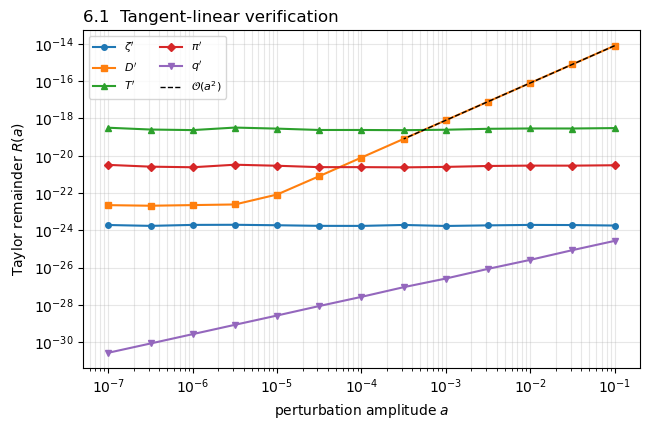

remainder slopes:  vor=0.00,  div=2.00,  T=0.04,  pi=0.05,  q=1.00
-> only the divergence remainder grows quadratically (slope ~2): it is the exact tangent-linear of the 0.5(u'^2+v'^2) term.  Every other tendency has slope <= 1 (no quadratic growth) -- it is linear, its remainder sitting at the round-off floor (q's floor scales with its tiny ~1e-3 magnitude, hence slope ~1).


In [3]:
amps = np.logspace(-1, -7, 13)
f0 = tvec(dyn_full, state_at(0.0))
Ldir = [x/1.0 for x in tvec(dyn_lin, state_at(1.0))]
rem = {v: [] for v in VARS}
for a in amps:
    fa = tvec(dyn_full, state_at(a))
    for i, v in enumerate(VARS):
        rem[v].append(nrm(fa[i] - f0[i] - a*Ldir[i]))

fig, ax = plt.subplots(figsize=(6.6, 4.4))
mk = dict(vor="o", div="s", T="^", q="v", pi="D")
lab = dict(vor=r"$\zeta'$", div=r"$D'$", T=r"$T'$", q=r"$q'$", pi=r"$\pi'$")
for v in VARS:
    ax.loglog(amps, np.maximum(rem[v], 1e-300), mk[v]+"-", ms=4, label=lab[v])
aref = amps[amps > 1e-4]
c = np.array(rem["div"])[amps > 1e-4][0]/aref[0]**2
ax.loglog(aref, c*aref**2, "k--", lw=1, label=r"$\mathcal{O}(a^2)$")
ax.set_xlabel("perturbation amplitude $a$")
ax.set_ylabel(r"Taylor remainder $R(a)$")
ax.set_title("6.1  Tangent-linear verification", loc="left")
ax.legend(ncol=2, fontsize=8); ax.grid(True, which="both", alpha=0.3)
fig.tight_layout(); plt.show()

reg = amps > 1e-4
slope = {v: np.polyfit(np.log(amps[reg]), np.log(np.array(rem[v])[reg]), 1)[0]
         for v in VARS}
print("remainder slopes:  " + ",  ".join(f"{v}={slope[v]:.2f}" for v in VARS))
print("-> only the divergence remainder grows quadratically (slope ~2): it is "
      "the exact tangent-linear of the 0.5(u'^2+v'^2) term.  Every other "
      "tendency has slope <= 1 (no quadratic growth) -- it is linear, its "
      "remainder sitting at the round-off floor (q's floor scales with its tiny "
      "~1e-3 magnitude, hence slope ~1).")

## 6.2 When does the nonlinearity matter?

The retained term is $\tfrac12(u'^2+v'^2)$, so its size relative to the linear
divergence tendency grows **linearly with the perturbation amplitude**. For the
small perturbations a linear model is meant for ($u'\sim$ a few m s$^{-1}$) it is
negligible; it becomes appreciable only at weather-amplitude anomalies. We
measure the fractional size of the nonlinear part of the divergence tendency as a
function of amplitude.

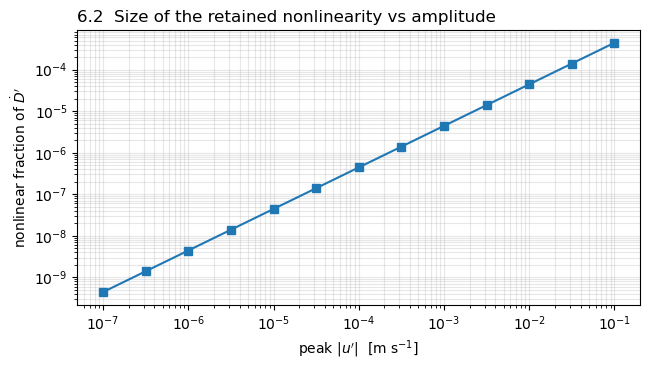

The nonlinear fraction is ~1% at |u'|~1 m/s and grows linearly; set Config(strictly_linear=True) to drop it and recover the exact TL model.


In [4]:
frac = []
for a in amps:
    st = state_at(a)
    d_full = tvec(dyn_full, st)[1]     # divergence tendency, full
    d_lin  = tvec(dyn_lin,  st)[1]     # divergence tendency, strictly linear
    frac.append(nrm(d_full - d_lin)/ (nrm(d_lin) or 1.0))
u_scale = amps*np.abs(dirn[0]).max()   # peak |u'| for each amplitude
fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.loglog(u_scale, frac, "s-")
ax.set_xlabel(r"peak $|u'|$  [m s$^{-1}$]")
ax.set_ylabel("nonlinear fraction of $\\dot D'$")
ax.set_title("6.2  Size of the retained nonlinearity vs amplitude", loc="left")
ax.grid(True, which="both", alpha=0.3); fig.tight_layout(); plt.show()
print("The nonlinear fraction is ~1% at |u'|~1 m/s and grows linearly; set "
      "Config(strictly_linear=True) to drop it and recover the exact TL model.")

### Notes

- `Dynamics(strictly_linear=True)` (and `Config(strictly_linear=True)`) remove
  the term, giving the **exact** tangent-linear operator — the one every other
  chapter of this guide uses.
- In the WK nonlinear model the basic state is held steady by a **residual
  forcing** $R=-\mathcal{N}(\bar x)$ that cancels its own nonlinear tendency, so
  the model integrates only the departure. PyLBM-Isca is formulated directly in
  the perturbation, so $R$ is implicit: the basic state never evolves, and the
  single quadratic term above is the only nonlinearity that can feed back on the
  perturbation.